# W2 — From Exploratory Analysis to Credible Validation
## DataCo Regional Sales Analysis — Group 67

**Members:** Ian Spikin Thomas, Juan Pablo Molina  
**Course:** Business Intelligence  
**Repository:** https://github.com/ians513/Business-Intelligence  
**Continuation:** Same project, business question and data source used in W1 and C1.

This notebook preserves the W1/C1 commercial line and strengthens it through explicit data validation, revised EDA, a sampling assessment, a leakage audit, and a defensible holdout/validation plan. The current project remains **descriptive and exploratory**; the holdout is therefore used as an independent robustness check rather than as a predictive-accuracy estimate.

# 1. W1/C1 continuity, decision and feedback

## Business problem and intended decision

**Business question:** Within the recorded DataCo transactions, how do category composition and purchasing intensity differ across regions, and which region–category combinations deserve further commercial investigation before assortment or promotional decisions are made?

**Intended user:** a commercial analyst or category manager.  
**Intended decision:** prioritize region–category combinations for further investigation, rather than directly prescribing a price or promotion change.

## Unit of observation and KPI

- **Unit of observation:** one **Order Item**. A row is one product line within an order; it is not one independent customer or one complete order.
- **Primary KPI:** **recorded units per represented order** = sum of `Order Item Quantity` / number of distinct `Order Id` values in the same eligible population.
- **Supporting measures:** recorded units, represented orders, within-region category share, item counts, and sample/coverage information.

The KPI is descriptive. It is not a measure of market demand, profitability, realized revenue, or causal promotional impact.

## Feedback-to-action table — grounded in the C1 presentation

The C1 presentation is an additional primary project artifact. No written instructor feedback was available to us, so the table below lists **self-audit findings** taken from the C1 presentation and from our own W2 checks.

| Source | Documented issue/evidence | W2 action | Evidence in W2 |
|---|---|---|---|
| C1 presentation, slide 10 (self-audit) | Canada is observed only between Aug 2016 and Jan 2017; regional windows differ. | Recompute a regional KPI for a common observed time window, report its row/order coverage, and qualify all comparisons. | Section 5: coverage table, month-overlap table and Figures 2–3 |
| C1 presentation, slides 5 and 11 (self-audit) | Regional volume and units/order tell different stories. Canada recorded 2,063 units and 7.09 units/order; Western Europe 9,563 represented orders and 5.64 units/order; Central America recorded 59,540 units. | Preserve the exact KPI denominator and jointly present KPI, units, orders, and observation windows; avoid equating high units/order with stronger performance. | Section 4 (C1 baseline comparison) and Figure 3 |
| C1 presentation, slides 7–8 (self-audit) | Across five large categories, discount-band differences in mean item quantity were only 0.008–0.045 units; causal effects were not identified. | Explicitly retain the noncausal discount conclusion; do not recommend deeper discounts from descriptive data. | Section 5, revised EDA conclusion |
| C1 presentation, slides 4 and 9 (self-audit) | Status exclusions and arithmetic checks were described (180,519 initial rows; 172,765 eligible items; no monetary discrepancies above 0.05 on the retained data), but W2 must show the reproducible check-by-check results. | Execute fresh validation checks, display counts and outcomes, and investigate any disagreement with C1 rather than forcing prior numbers. | Section 4: check table, row-count audit and C1 baseline comparison |
| W2 self-audit (monthly structure check) | From October 2017 every order has one item with one unit, while earlier months have about 3 items per order. This was not visible in C1. | Flag it as a limitation, show its effect on the regional KPI (Figure 3) and on the test partition, and do not change the cleaning rules or the split because of it. | Section 4 (check 9), Figure 3 and Section 8 |
| W2 self-audit (category labels) | Some category labels have trailing spaces (for example "Baby " and "Books "). | Trim the labels, confirm that the number of categories does not change and that no rows are dropped. | Section 4 (check 8) |

## Explicit changes to the C1 conclusion

**Retained:** The C1 presentation reported differences between raw unit totals, represented-order counts, and units per order. Category mixes appeared similar in many regions; Cleats, Women's Apparel and Indoor/Outdoor Games were leading categories. Recorded discount patterns did **not** justify a causal claim or deeper discounts.

**Changed in W2:** C1 read the whole-period gap in units per order (for example Western Europe 5.64 against Central America 6.61) as a regional difference. In W2 most of that gap disappears: before October 2017 Western Europe has 6.50 and Central America 6.61, and the five largest regions range only from 6.33 to 6.61. The low whole-period values for Western Europe, Northern Europe and Oceania come from the months after October 2017, when every order has a single item with one unit. Canada's 7.09 is not affected by this (its dates are Aug 2016–Jan 2017), but it rests on only 291 orders in five months. The comparison over shared dates that we built for Figure 3 is also weaker than expected, because no single month has records in all five regions, so we do not use it to rank regions.

**Strengthened in W2:** the C1 baseline numbers are now recomputed from the data (Section 4), and the validation, sampling, leakage and holdout sections are executed.


### C1 evidence baseline — source: Group 67 C1 presentation

The following values were **reported in the C1 slides**, not recomputed in this markdown cell. Section 4 recomputes them from the source file.

| C1 reference | Reported evidence |
|---|---|
| Slide 4: Data preparation | 180,519 Order Item rows; 53 variables; 172,765 retained items; 62,897 represented orders; exclusions: 3,692 `CANCELED` and 4,062 `SUSPECTED_FRAUD` |
| Slide 5: Regional comparison | Canada: 2,063 recorded units, 7.09 units/order; Western Europe: 9,563 represented orders, 5.64 units/order; Central America: 59,540 recorded units |
| Slide 6: Category heatmap | Cleats, Women's Apparel and Indoor/Outdoor Games among the major categories across many regions; shares describe observed transactions, not total market demand |
| Slides 7–8: Discount bands and robustness | Across the five largest categories, reported max–min differences of mean item quantity by discount band ranged from 0.008 to 0.045 units; largest category-share difference after status exclusions ≈0.54 percentage points; no retained monetary arithmetic discrepancies above 0.05 |
| Slide 9: Main limitation | Canada's observed dates were Aug 2016–Jan 2017 and regional observation windows were unequal |
| Slide 10: Future work | Potential monthly region–category forecast and a filtering dashboard, subject to coverage limitations |

The values above come from the C1 slides. The comparison table in Section 4 shows which of them we could reproduce.

# 2. Setup, reproducibility and data loading

Use a fixed seed for every random operation. The loader accepts the source CSV or the Parquet copy used in C1. Keep the original file unchanged.

In [1]:
from pathlib import Path
import hashlib
import platform
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEED = 67
rng = np.random.default_rng(SEED)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

candidates = [
    Path("data/DataCoSupplyChainDataset.csv"),
    Path("../data/DataCoSupplyChainDataset.csv"),
    Path("data/dataset.parquet"),
    Path("../data/dataset.parquet"),
    Path("DataCoSupplyChainDataset.csv"),
    Path("dataset.parquet"),
]

data_path = next((p for p in candidates if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError(
        "Dataset not found. Place DataCoSupplyChainDataset.csv or dataset.parquet in data/."
    )

if data_path.suffix.lower() == ".csv":
    df = pd.read_csv(data_path, encoding="ISO-8859-1", low_memory=False)
else:
    df = pd.read_parquet(data_path)

file_hash = hashlib.sha256(data_path.read_bytes()).hexdigest()

print("Dataset:", data_path.as_posix())
print("SHA-256:", file_hash)
print("Shape:", df.shape)
print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Random seed:", SEED)

Dataset: dataset.parquet
SHA-256: 404f96ba08c018d4c630577d3379da0d5397ae427a2e59620085bda066871ca1
Shape: (180519, 53)
Python: 3.12.10
pandas: 3.0.5
NumPy: 2.5.3
Matplotlib: 3.11.1
Random seed: 67


In [2]:
ORDER_DATE = "order date (DateOrders)"
SHIP_DATE = "shipping date (DateOrders)"

work = df.copy()
work[ORDER_DATE] = pd.to_datetime(work[ORDER_DATE], errors="coerce")
if SHIP_DATE in work.columns:
    work[SHIP_DATE] = pd.to_datetime(work[SHIP_DATE], errors="coerce")
work["_status_norm"] = work["Order Status"].astype("string").str.strip().str.upper()

print("Observed date coverage:", work[ORDER_DATE].min(), "to", work[ORDER_DATE].max())
print("Unique order items:", work["Order Item Id"].nunique())
print("Unique orders:", work["Order Id"].nunique())
print("Unique customers:", work["Customer Id"].nunique())
print("Regions:", work["Order Region"].nunique())
print("Categories:", work["Category Name"].nunique())

Observed date coverage: 2015-01-01 00:00:00 to 2018-01-31 23:38:00
Unique order items: 180519
Unique orders: 65752
Unique customers: 20652
Regions: 23
Categories: 50


# 3. Concise data dictionary

The table focuses on variables used for the W2 business question, validation and split design. “Acceptable values” are analytical constraints, not claims about every possible value in the original information system.

In [3]:
data_dictionary = pd.DataFrame([
    ["Order Item Id", "integer-like identifier", "non-missing; unique at row level", "Missing would prevent item-level traceability"],
    ["Order Id", "integer-like identifier", "non-missing; repeated across items is allowed", "Missing would break order-level denominators/groups"],
    ["Customer Id", "integer-like identifier", "non-missing where available; repeated is allowed", "Missing would limit customer-level grouping"],
    [ORDER_DATE, "datetime", "parseable; within supplied historical coverage", "Missing/unparseable means order time is unknown"],
    [SHIP_DATE, "datetime", "parseable when used; should not precede order date", "Missing/unparseable means shipment time is unknown"],
    ["Order Region", "categorical string", "non-missing; observed source categories", "Missing means region is unavailable"],
    ["Category Id", "integer-like category key", "should map consistently to Category Name", "Missing would weaken category mapping"],
    ["Category Name", "categorical string", "non-missing; observed source categories", "Missing means product category is unavailable"],
    ["Order Item Quantity", "numeric/integer", "> 0 and whole-number quantity", "Missing means recorded quantity is unavailable"],
    ["Order Item Product Price", "numeric", ">= 0", "Missing means recorded unit price is unavailable"],
    ["Order Item Discount Rate", "numeric proportion", "0 to 1 inclusive", "Missing means discount rate is unavailable"],
    ["Order Item Discount", "numeric amount", ">= 0 and not greater than Sales within tolerance", "Missing means discount amount is unavailable"],
    ["Sales", "numeric amount", ">= 0; expected to match price × quantity within tolerance", "Missing means recorded gross sales amount is unavailable"],
    ["Order Item Total", "numeric amount", ">= 0; expected to match Sales − Discount within tolerance", "Missing means recorded post-discount item amount is unavailable"],
    ["Order Status", "categorical string", "one of the documented/observed status labels", "Missing means transaction state is unknown"],
], columns=["Variable", "Expected type", "Acceptable values / constraint", "Meaning of missingness"])

display(data_dictionary)

,Variable,Expected type,Acceptable values / constraint,Meaning of missingness
0,Order Item Id,integer-like identifier,non-missing; unique at row level,Missing would prevent item-level traceability
1,Order Id,integer-like identifier,non-missing; repeated across items is allowed,Missing would break order-level denominators/g...
2,Customer Id,integer-like identifier,non-missing where available; repeated is allowed,Missing would limit customer-level grouping
3,order date (DateOrders),datetime,parseable; within supplied historical coverage,Missing/unparseable means order time is unknown
4,shipping date (DateOrders),datetime,parseable when used; should not precede order ...,Missing/unparseable means shipment time is unk...
5,Order Region,categorical string,non-missing; observed source categories,Missing means region is unavailable
6,Category Id,integer-like category key,should map consistently to Category Name,Missing would weaken category mapping
7,Category Name,categorical string,non-missing; observed source categories,Missing means product category is unavailable
8,Order Item Quantity,numeric/integer,> 0 and whole-number quantity,Missing means recorded quantity is unavailable
9,Order Item Product Price,numeric,>= 0,Missing means recorded unit price is unavailable


# 4. Programmatic data validation

Each check below reports its result and an explicit treatment. Rows are never dropped silently. The commercial subset retains the C1 rule: exclude `CANCELED` and `SUSPECTED_FRAUD` only after essential-field validity has been evaluated.

In [4]:
required = [
    "Order Item Id", "Order Id", "Customer Id", ORDER_DATE, "Order Region",
    "Category Id", "Category Name", "Order Item Quantity",
    "Order Item Product Price", "Order Item Discount Rate",
    "Order Item Discount", "Sales", "Order Item Total", "Order Status"
]
missing_columns = [c for c in required if c not in work.columns]
assert not missing_columns, f"Missing required columns: {missing_columns}"

expected_statuses = {
    "COMPLETE", "PENDING_PAYMENT", "PROCESSING", "PENDING", "CLOSED",
    "ON_HOLD", "SUSPECTED_FRAUD", "CANCELED", "PAYMENT_REVIEW"
}

validation_rows = []
def add_check(name, failures, evidence, treatment, action=None):
    validation_rows.append({
        "check": name,
        "failures": int(failures),
        "evidence": evidence,
        "treatment_if_failed": treatment,
        "action_taken": action if action is not None else (
            "None needed: 0 failures" if int(failures) == 0 else treatment)
    })

# 1) Key integrity
key_fail = (
    work["Order Item Id"].isna().sum()
    + work["Order Item Id"].duplicated().sum()
    + work["Order Id"].isna().sum()
)
add_check(
    "Key integrity",
    key_fail,
    f"missing item IDs={work['Order Item Id'].isna().sum()}, duplicate item IDs={work['Order Item Id'].duplicated().sum()}, missing order IDs={work['Order Id'].isna().sum()}",
    "Retain if zero; otherwise exclude invalid essential rows and report counts."
)

# 2) Numeric domains
qty = pd.to_numeric(work["Order Item Quantity"], errors="coerce")
price = pd.to_numeric(work["Order Item Product Price"], errors="coerce")
disc_rate = pd.to_numeric(work["Order Item Discount Rate"], errors="coerce")
disc = pd.to_numeric(work["Order Item Discount"], errors="coerce")
sales = pd.to_numeric(work["Sales"], errors="coerce")
item_total = pd.to_numeric(work["Order Item Total"], errors="coerce")

numeric_invalid = (
    qty.isna() | (qty <= 0) | (qty % 1 != 0)
    | price.isna() | (price < 0)
    | disc_rate.isna() | ~disc_rate.between(0, 1)
    | disc.isna() | (disc < 0)
    | sales.isna() | (sales < 0)
    | item_total.isna() | (item_total < 0)
)
add_check(
    "Numeric domains and types",
    numeric_invalid.sum(),
    "Quantity must be a positive whole number; monetary fields non-negative; discount rate in [0,1].",
    "Exclude only rows that fail essential analytical constraints; report count before filtering."
)

# 3) Category/status consistency
unexpected_status = ~work["_status_norm"].isin(expected_statuses) | work["_status_norm"].isna()
add_check(
    "Order-status consistency",
    unexpected_status.sum(),
    "Unexpected/missing normalized statuses: " + str(sorted(work.loc[unexpected_status, "_status_norm"].dropna().unique().tolist())),
    "Retain known statuses; flag unexpected statuses for review before analysis."
)

# 4) Date logic
order_date_bad = work[ORDER_DATE].isna()
if SHIP_DATE in work.columns:
    ship_date_bad = work[SHIP_DATE].isna() | (work[SHIP_DATE] < work[ORDER_DATE])
else:
    ship_date_bad = pd.Series(False, index=work.index)
date_failures = order_date_bad | ship_date_bad
add_check(
    "Date parseability and chronology",
    date_failures.sum(),
    f"unparseable order dates={order_date_bad.sum()}, missing/reversed shipping dates={ship_date_bad.sum()}",
    "Order date is essential for W2. Shipping-date issues are flagged and are not used to silently remove commercial rows."
)

# 5) Within-order consistency
order_consistency = work.groupby("Order Id", dropna=False).agg(
    regions=("Order Region", "nunique"),
    order_dates=(ORDER_DATE, "nunique")
)
conflicting_orders = ((order_consistency["regions"] > 1) | (order_consistency["order_dates"] > 1)).sum()
add_check(
    "Within-order region/date consistency",
    conflicting_orders,
    "An Order Id should not map to multiple regions or order timestamps in this analysis.",
    "Flag conflicts; do not split items from one order across analytical partitions."
)

# 6) Category mapping consistency
category_mapping = work.groupby("Category Id")["Category Name"].nunique(dropna=True)
category_conflicts = (category_mapping > 1).sum()
add_check(
    "Category Id → Category Name consistency",
    category_conflicts,
    f"category IDs mapping to >1 category name={category_conflicts}",
    "Flag conflicting mappings; retain only after source semantics are resolved."
)

# 7) Monetary arithmetic
sales_mismatch = (sales - price * qty).abs().gt(0.05)
total_mismatch = (item_total - (sales - disc)).abs().gt(0.05)
discount_gt_sales = disc.gt(sales + 0.05)
monetary_fail = sales_mismatch | total_mismatch | discount_gt_sales
add_check(
    "Monetary arithmetic",
    monetary_fail.sum(),
    f"Sales≠price×qty={sales_mismatch.sum()}, Total≠Sales−Discount={total_mismatch.sum()}, Discount>Sales={discount_gt_sales.sum()}",
    "Flag discrepancies; do not reinterpret recorded monetary fields as realized revenue."
)

# 8) Whitespace in category labels
category_raw = work["Category Name"].astype("string")
category_trimmed = category_raw.str.strip()
category_ws_rows = int((category_raw != category_trimmed).sum())
labels_before = category_raw.nunique()
labels_after = category_trimmed.nunique()
rows_before_trim = len(work)
work["Category Name"] = category_trimmed
add_check(
    "Category label whitespace",
    category_ws_rows,
    f"rows with leading/trailing spaces={category_ws_rows}; category labels before={labels_before}, after trimming={labels_after}; rows before={rows_before_trim}, after={len(work)}",
    "Trim labels; confirm that no labels merge and no rows are dropped.",
    f"Corrected: labels trimmed in `work`; label count {labels_before} -> {labels_after}; rows {rows_before_trim} -> {len(work)}"
)

# 9) Order structure over time: items per order and share of one-unit items, by month
monthly_structure = work.groupby(work[ORDER_DATE].dt.to_period("M")).agg(
    items=("Order Item Id", "size"),
    orders=("Order Id", "nunique"),
    one_unit_share=("Order Item Quantity", lambda s: (pd.to_numeric(s, errors="coerce") == 1).mean())
)
monthly_structure["items_per_order"] = monthly_structure["items"] / monthly_structure["orders"]
single_item_months = monthly_structure[monthly_structure["items_per_order"] <= 1.1]
typical_ipo = monthly_structure.loc[monthly_structure["items_per_order"] > 1.1, "items_per_order"].median()
BREAK_START = single_item_months.index.min().to_timestamp()
break_rows = int(single_item_months["items"].sum())
add_check(
    "Order structure stable over time",
    break_rows,
    f"{len(single_item_months)} months from {BREAK_START:%Y-%m} have about 1 item per order (typical earlier month: {typical_ipo:.2f}); "
    f"share of one-unit items in those months: {single_item_months['one_unit_share'].min():.1%} to {single_item_months['one_unit_share'].max():.1%}",
    "Flag as a limitation.",
    f"Retained and flagged as a limitation: these {break_rows:,} rows pass every other check, but from {BREAK_START:%Y-%m} orders are recorded as one item of one unit. Cleaning rules and split are not changed because of it."
)

validation_results = pd.DataFrame(validation_rows)
pd.set_option("display.max_colwidth", None)
display(validation_results)
display(monthly_structure.tail(6).round(3))

,check,failures,evidence,treatment_if_failed,action_taken
0,Key integrity,0,"missing item IDs=0, duplicate item IDs=0, missing order IDs=0",Retain if zero; otherwise exclude invalid essential rows and report counts.,None needed: 0 failures
1,Numeric domains and types,0,"Quantity must be a positive whole number; monetary fields non-negative; discount rate in [0,1].",Exclude only rows that fail essential analytical constraints; report count before filtering.,None needed: 0 failures
2,Order-status consistency,0,Unexpected/missing normalized statuses: [],Retain known statuses; flag unexpected statuses for review before analysis.,None needed: 0 failures
3,Date parseability and chronology,0,"unparseable order dates=0, missing/reversed shipping dates=0",Order date is essential for W2. Shipping-date issues are flagged and are not used to silently remove commercial rows.,None needed: 0 failures
4,Within-order region/date consistency,0,An Order Id should not map to multiple regions or order timestamps in this analysis.,Flag conflicts; do not split items from one order across analytical partitions.,None needed: 0 failures
5,Category Id → Category Name consistency,0,category IDs mapping to >1 category name=0,Flag conflicting mappings; retain only after source semantics are resolved.,None needed: 0 failures
6,Monetary arithmetic,0,"Sales≠price×qty=0, Total≠Sales−Discount=0, Discount>Sales=0",Flag discrepancies; do not reinterpret recorded monetary fields as realized revenue.,None needed: 0 failures
7,Category label whitespace,1475,"rows with leading/trailing spaces=1475; category labels before=50, after trimming=50; rows before=180519, after=180519",Trim labels; confirm that no labels merge and no rows are dropped.,Corrected: labels trimmed in `work`; label count 50 -> 50; rows 180519 -> 180519
8,Order structure stable over time,8557,4 months from 2017-10 have about 1 item per order (typical earlier month: 3.00); share of one-unit items in those months: 95.8% to 100.0%,Flag as a limitation.,"Retained and flagged as a limitation: these 8,557 rows pass every other check, but from 2017-10 orders are recorded as one item of one unit. Cleaning rules and split are not changed because of it."


,items,orders,one_unit_share,items_per_order
order date (DateOrders),,,,
2017-08,5305,1768,0.571,3.001
2017-09,5189,1723,0.583,3.012
2017-10,2255,2101,0.958,1.073
2017-11,2055,2055,1.000,1.000
2017-12,2124,2124,1.000,1.000
2018-01,2123,2123,1.000,1.000


In [5]:
# Explicit row-count audit and commercial population construction
rows_input = len(work)

essential_valid = (
    work["Order Item Id"].notna()
    & ~work["Order Item Id"].duplicated(keep=False)
    & work["Order Id"].notna()
    & work[ORDER_DATE].notna()
    & work["Order Region"].notna()
    & work["Category Name"].notna()
    & ~numeric_invalid
    & ~unexpected_status
)

rows_after_essential = int(essential_valid.sum())
excluded_status_mask = work["_status_norm"].isin(["CANCELED", "SUSPECTED_FRAUD"])
commercial_mask = essential_valid & ~excluded_status_mask
commercial = work.loc[commercial_mask].copy()
rows_final = len(commercial)

row_audit = pd.DataFrame({
    "stage": [
        "Input rows",
        "After essential validation",
        "Excluded CANCELED/SUSPECTED_FRAUD among valid rows",
        "Final analytical dataset"
    ],
    "rows": [
        rows_input,
        rows_after_essential,
        int((essential_valid & excluded_status_mask).sum()),
        rows_final
    ]
})

display(row_audit)
print("Rows removed by essential validation:", rows_input - rows_after_essential)
print("Rows excluded by status rule:", rows_after_essential - rows_final)
print("Final represented orders:", commercial["Order Id"].nunique())

,stage,rows
0,Input rows,180519
1,After essential validation,180519
2,Excluded CANCELED/SUSPECTED_FRAUD among valid rows,7754
3,Final analytical dataset,172765


Rows removed by essential validation: 0
Rows excluded by status rule: 7754
Final represented orders: 62897


**Treatment rule:** C1 excluded `CANCELED` and `SUSPECTED_FRAUD` as a declared commercial-analysis assumption. W2 keeps that rule for continuity. This does **not** imply that every remaining status is a realized sale. Any failed non-essential check is reported as a limitation rather than being silently removed.

Two checks led to action. Check 8 trimmed trailing spaces in category labels (the label count and the row count do not change). Check 9 flagged that from October 2017 every order has one item of one unit. It is kept as a **limitation**, not as an exclusion, because those rows pass every other check. We noticed it while looking at the whole history, which is another case of the full-data exploration mentioned in Section 8; we did not change the cleaning rules or the split because of it.

## C1 baseline comparison

The table recomputes the numbers reported in the C1 slides from the data used in this notebook. A mismatch would be investigated, not forced.

In [6]:
def region_stats(region):
    sub = commercial[commercial["Order Region"].eq(region)]
    units = sub["Order Item Quantity"].sum()
    orders = sub["Order Id"].nunique()
    return units, orders, units / orders

can_units, can_orders, can_upo = region_stats("Canada")
we_units, we_orders, we_upo = region_stats("Western Europe")
ca_units, ca_orders, ca_upo = region_stats("Central America")

c1_rows = [
    ["Order Item rows", 180519, len(df)],
    ["Variables", 53, df.shape[1]],
    ["Retained items", 172765, len(commercial)],
    ["Represented orders", 62897, commercial["Order Id"].nunique()],
    ["Excluded CANCELED", 3692, int((work["_status_norm"] == "CANCELED").sum())],
    ["Excluded SUSPECTED_FRAUD", 4062, int((work["_status_norm"] == "SUSPECTED_FRAUD").sum())],
    ["Canada recorded units", 2063, can_units],
    ["Canada units per order", 7.09, round(can_upo, 2)],
    ["Western Europe represented orders", 9563, we_orders],
    ["Western Europe units per order", 5.64, round(we_upo, 2)],
    ["Central America recorded units", 59540, ca_units],
]
c1_check = pd.DataFrame(c1_rows, columns=["C1 value", "reported in C1", "recomputed in W2"])
c1_check["match"] = np.isclose(
    c1_check["reported in C1"].astype(float), c1_check["recomputed in W2"].astype(float), atol=0.005
)
display(c1_check)
print("C1 values that do not match:", int((~c1_check["match"]).sum()))

,C1 value,reported in C1,recomputed in W2,match
0,Order Item rows,180519.00,180519.00,True
1,Variables,53.00,53.00,True
2,Retained items,172765.00,172765.00,True
3,Represented orders,62897.00,62897.00,True
4,Excluded CANCELED,3692.00,3692.00,True
5,Excluded SUSPECTED_FRAUD,4062.00,4062.00,True
6,Canada recorded units,2063.00,2063.00,True
7,Canada units per order,7.09,7.09,True
8,Western Europe represented orders,9563.00,9563.00,True
9,Western Europe units per order,5.64,5.64,True


C1 values that do not match: 0


# 5. Revised exploratory data analysis (EDA)

This section keeps three things in view: explicit denominators, explicit coverage, and no causal reading. Monetary fields are recorded amounts, not verified realized revenue.

## Descriptive statistics and missingness

In [7]:
summary = pd.DataFrame({
    "metric": [
        "Analytical order items", "Represented orders", "Customers",
        "Recorded units", "Units per represented order", "Regions", "Categories"
    ],
    "value": [
        len(commercial),
        commercial["Order Id"].nunique(),
        commercial["Customer Id"].nunique(),
        commercial["Order Item Quantity"].sum(),
        commercial["Order Item Quantity"].sum() / commercial["Order Id"].nunique(),
        commercial["Order Region"].nunique(),
        commercial["Category Name"].nunique(),
    ]
})
display(summary)

key_missing = commercial[[
    "Order Item Id", "Order Id", ORDER_DATE, "Order Region", "Category Name",
    "Order Item Quantity", "Order Item Discount Rate", "Sales"
]].isna().sum().to_frame("missing")
display(key_missing)

,metric,value
0,Analytical order items,172765.000000
1,Represented orders,62897.000000
2,Customers,20261.000000
3,Recorded units,367591.000000
4,Units per represented order,5.844333
5,Regions,23.000000
6,Categories,50.000000


,missing
Order Item Id,0
Order Id,0
order date (DateOrders),0
Order Region,0
Category Name,0
Order Item Quantity,0
Order Item Discount Rate,0
Sales,0


## Figure 1 — Distribution of order-item quantity

**Denominator:** retained analytical order items.  
**Unit:** recorded product units on one order item.

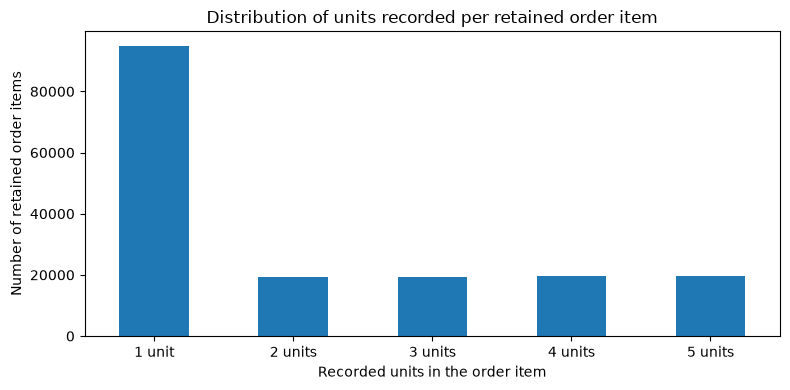

**Observation.** The most frequent quantity is **1 unit**, in **54.9%** of retained order items; the other quantities are about equally common (11.2% to 11.3% each). Each bar counts order items, not orders or customers, and the figure only describes observed transactions: it says nothing about non-purchases, unmet demand or causes.

In [8]:
qty_counts = commercial["Order Item Quantity"].value_counts().sort_index()
ax = qty_counts.plot(kind="bar", figsize=(8, 4))
ax.set_title("Distribution of units recorded per retained order item")
ax.set_xlabel("Recorded units in the order item")
ax.set_ylabel("Number of retained order items")
ax.set_xticklabels(
    [f"{int(q)} unit" if q == 1 else f"{int(q)} units" for q in qty_counts.index],
    rotation=0,
)
plt.tight_layout()
plt.show()

mode_qty = qty_counts.idxmax()
mode_count = int(qty_counts.max())
mode_share = mode_count / len(commercial) * 100

other_shares = qty_counts.drop(mode_qty) / len(commercial) * 100

display(Markdown(
    f"**Observation.** The most frequent quantity is **{int(mode_qty)} unit**, in **{mode_share:.1f}%** of retained order items; "
    f"the other quantities are about equally common ({other_shares.min():.1f}% to {other_shares.max():.1f}% each). "
    "Each bar counts order items, not orders or customers, and the figure only describes observed transactions: it says nothing about non-purchases, unmet demand or causes."
))


## Coverage repair before regional comparison

C1 showed that regional observation windows are unequal. There is no single date range shared by all 23 regions, so a comparison across every region would fail and would also be misleading. Figures 2–3 therefore focus on the five regions with the largest retained unit totals. Figure 2 first locates the common window in time; Figure 3 then compares the regional KPI during those shared dates. The selection rule and the common dates are calculated below. These dates only run from the latest first record to the earliest last record, so a region can still be inactive for long stretches inside them; the table after the coverage output counts the months in which each region really has records.

In [9]:
region_coverage = commercial.groupby("Order Region").agg(
    first_date=(ORDER_DATE, "min"),
    last_date=(ORDER_DATE, "max"),
    items=("Order Item Id", "size"),
    orders=("Order Id", "nunique")
).sort_values("first_date")

display(region_coverage)

# Use the five regions with the largest retained unit totals.
top5_regions = (
    commercial.groupby("Order Region")["Order Item Quantity"]
    .sum()
    .nlargest(5)
    .index
    .tolist()
)

focus_coverage = region_coverage.loc[top5_regions]
common_start = focus_coverage["first_date"].max()
common_end = focus_coverage["last_date"].min()

common = commercial.loc[
    commercial["Order Region"].isin(top5_regions)
    & commercial[ORDER_DATE].between(common_start, common_end, inclusive="both")
].copy()

print("Regions compared:", top5_regions)
print("Common comparison window:", common_start, "to", common_end)
print("Rows in common window:", len(common))
print("Orders in common window:", common["Order Id"].nunique())
display(focus_coverage)

# How many months inside the window does each region really have records?
window_months = pd.period_range(common_start, common_end, freq="M")
common_activity = (
    common.assign(order_month=common[ORDER_DATE].dt.to_period("M"))
    .groupby(["order_month", "Order Region"]).size()
    .unstack(fill_value=0)
    .reindex(window_months, fill_value=0)
)
months_active = (common_activity > 0).sum().to_frame("months_with_records_in_window")
months_active["months_in_window"] = len(window_months)
display(months_active)
months_all_five = int((common_activity > 0).all(axis=1).sum())
print("Months in the window with records in all five regions:", months_all_five)


,first_date,last_date,items,orders
Order Region,,,,
Central America,2015-01-01 00:00:00,2017-06-13 14:09:00,27174,9001
South America,2015-01-01 00:21:00,2017-06-17 23:16:00,14184,4738
Caribbean,2015-01-01 12:57:00,2017-06-12 04:31:00,7951,2675
Northern Europe,2015-05-31 06:47:00,2017-11-10 20:57:00,9408,3564
Western Europe,2015-05-31 09:57:00,2017-11-10 22:42:00,25867,9563
Southern Europe,2015-05-31 14:09:00,2017-11-10 21:18:00,9030,3390
Eastern Asia,2015-10-24 05:53:00,2018-01-31 18:44:00,6973,3171
Southeast Asia,2015-10-24 07:17:00,2018-01-31 23:17:00,9136,4173
Oceania,2015-10-24 08:20:00,2018-01-31 23:38:00,9733,4175


Regions compared: ['Central America', 'Western Europe', 'South America', 'Oceania', 'Northern Europe']
Common comparison window: 2015-10-24 08:20:00 to 2017-06-13 14:09:00
Rows in common window: 28800
Orders in common window: 9573


,first_date,last_date,items,orders
Order Region,,,,
Central America,2015-01-01 00:00:00,2017-06-13 14:09:00,27174,9001
Western Europe,2015-05-31 09:57:00,2017-11-10 22:42:00,25867,9563
South America,2015-01-01 00:21:00,2017-06-17 23:16:00,14184,4738
Oceania,2015-10-24 08:20:00,2018-01-31 23:38:00,9733,4175
Northern Europe,2015-05-31 06:47:00,2017-11-10 20:57:00,9408,3564


,months_with_records_in_window,months_in_window
Order Region,,
Central America,6,21
Northern Europe,6,21
Oceania,7,21
South America,6,21
Western Europe,6,21


Months in the window with records in all five regions: 0


## Figure 2 — Monthly recorded units for the five largest regions

This view places the common comparison window in the temporal context of the five regions with the largest total retained recorded units. The dashed and dotted vertical lines mark the latest first record and the earliest last record among the five regions. The dash-dot line marks the month from which orders have a single item (Section 4, check 9).

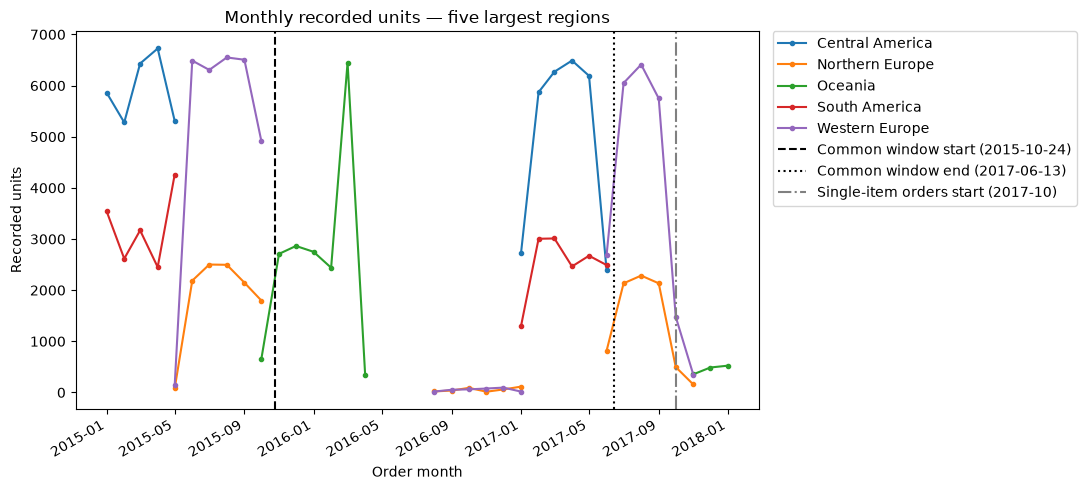

,months_with_records
Order Region,
Northern Europe,18
Western Europe,18
Central America,11
South America,11
Oceania,10


**Observation.** The dashed and dotted lines mark **2015-10-24** and **2017-06-13**, the latest first record and the earliest last record among the five regions. Inside those dates the regions are active in different blocks of months, and the number of months with records in all five of them is 0. The window is therefore a date range, not a common period. Recorded units for the two European regions fall after the gray line; the chart does not explain why.

In [10]:
commercial["order_month"] = commercial[ORDER_DATE].dt.to_period("M").dt.to_timestamp()

monthly = (
    commercial.loc[commercial["Order Region"].isin(top5_regions)]
    .groupby(["order_month", "Order Region"])["Order Item Quantity"]
    .sum()
    .unstack()
)

ax = monthly.plot(figsize=(11, 5), marker="o", markersize=3)
ax.axvline(common_start, color="black", linestyle="--", linewidth=1.5,
           label=f"Common window start ({common_start:%Y-%m-%d})")
ax.axvline(common_end, color="black", linestyle=":", linewidth=1.5,
           label=f"Common window end ({common_end:%Y-%m-%d})")
ax.axvline(BREAK_START, color="gray", linestyle="-.", linewidth=1.5,
           label=f"Single-item orders start ({BREAK_START:%Y-%m})")
ax.set_title("Monthly recorded units — five largest regions")
ax.set_xlabel("Order month")
ax.set_ylabel("Recorded units")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0)
plt.tight_layout()
plt.show()

months_present = monthly.notna().sum().sort_values(ascending=False)
display(months_present.to_frame("months_with_records"))
display(Markdown(
    f"**Observation.** The dashed and dotted lines mark **{common_start:%Y-%m-%d}** and **{common_end:%Y-%m-%d}**, "
    "the latest first record and the earliest last record among the five regions. Inside those dates the regions are active in different blocks of months, "
    f"and the number of months with records in all five of them is {months_all_five}. The window is therefore a date range, not a common period. "
    "Recorded units for the two European regions fall after the gray line; the chart does not explain why."
))


## Figure 3 — Regional KPI for the five largest regions

**KPI denominator:** distinct represented orders within each region and period.  
Three versions are shown: the whole period, the shared dates from Figure 2, and the whole period before the single-item orders start (Section 4, check 9). None of them is a true common period, because the regions are active in different months, so the figure is read as a sensitivity check and not as a ranking.

,full_period,common_window,before_single_item_orders
Order Region,,,
South America,6.538,6.386,6.538
Oceania,4.693,6.490,6.490
Western Europe,5.641,6.551,6.497
Central America,6.615,6.597,6.615
Northern Europe,5.488,6.720,6.328


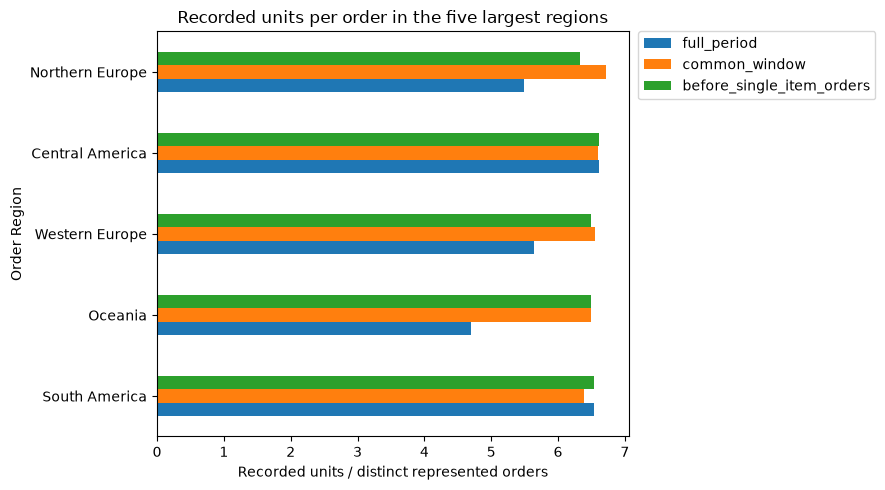

**Observation.** Over whole periods the five regions range from 4.69 to 6.61 units per order. Before the single-item orders start (2017-10) the same regions range from 6.33 to 6.61, so most of the gap in the whole-period bars comes from that change in how orders are recorded and not from the regions themselves. The shared dates give 6.39 to 6.72, but they are not a common period (no month has records in all five regions). We do not rank the regions. Assortment, customer mix, availability or reporting differences could still explain what remains.

In [11]:
def region_kpi(frame):
    result = frame.groupby("Order Region").agg(
        units=("Order Item Quantity", "sum"),
        orders=("Order Id", "nunique")
    )
    result["units_per_order"] = result["units"] / result["orders"]
    return result

full_region = region_kpi(
    commercial.loc[commercial["Order Region"].isin(top5_regions)]
)
common_region = region_kpi(common)
before_break_region = region_kpi(
    commercial.loc[
        commercial["Order Region"].isin(top5_regions)
        & (commercial[ORDER_DATE] < BREAK_START)
    ]
)

comparison = pd.DataFrame({
    "full_period": full_region["units_per_order"],
    "common_window": common_region["units_per_order"],
    "before_single_item_orders": before_break_region["units_per_order"]
}).sort_values("common_window")

display(comparison.round(3))

ax = comparison.plot(kind="barh", figsize=(9, 5))
ax.set_title("Recorded units per order in the five largest regions")
ax.set_xlabel("Recorded units / distinct represented orders")
ax.set_ylabel("Order Region")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0)
plt.tight_layout()
plt.show()

def kpi_range(column):
    return f"{comparison[column].min():.2f} to {comparison[column].max():.2f}"

display(Markdown(
    f"**Observation.** Over whole periods the five regions range from {kpi_range('full_period')} units per order. "
    f"Before the single-item orders start ({BREAK_START:%Y-%m}) the same regions range from {kpi_range('before_single_item_orders')}, "
    "so most of the gap in the whole-period bars comes from that change in how orders are recorded and not from the regions themselves. "
    f"The shared dates give {kpi_range('common_window')}, but they are not a common period (no month has records in all five regions). "
    "We do not rank the regions. Assortment, customer mix, availability or reporting differences could still explain what remains."
))


## Revised EDA conclusion

**Observations.** The quantity distribution describes recorded order lines. The monthly and regional views show that time coverage and the way orders are recorded affect the comparison: the regional gaps in whole-period units per order mostly disappear before October 2017, and no month has records in all five of the largest regions. The Figure 3 comparison is therefore a sensitivity check, not a ranking.

**Assumptions.** Units per represented order is read as a descriptive measure of purchasing intensity within the retained transactions. `CANCELED` and `SUSPECTED_FRAUD` rows are excluded as in C1. Rows from October 2017 onward are kept even though they look recorded differently.

**What the results do not show.** They do not prove that one region has stronger market demand, that discounts caused higher quantities, or that recorded sales equal realized revenue. Assortment, customer mix, product availability and reporting remain possible explanations.

**Recommendation.** Before using these numbers to prioritize region–category combinations, ask DataCo why orders are recorded as single items from October 2017, and compare regions only over months in which they are all observed.


# 6. Sampling and representativeness

## Population definitions

- **Target population:** the commercial transactions that a DataCo commercial analyst would want to generalize to when making assortment/investigation decisions. The supplied data do not prove that they form a random or complete sample of that target.
- **Observed population:** the 180,519 supplied Order Item records covering the source's observed historical period.
- **Final analytical dataset:** rows that pass the declared essential checks and exclude `CANCELED` and `SUSPECTED_FRAUD`, preserving the C1 rule.

### Plausible sampling / coverage biases

1. **Temporal and geographic coverage bias:** regions and categories have different observation windows, so whole-period comparisons combine time with geography/product coverage.
2. **Transaction-only selection:** the file contains recorded order items, not customer exposures, lost sales, non-purchases, stock-outs or the full addressable market.
3. **Status-rule selection:** removing canceled and suspected-fraud items changes the analytical population and may affect some segments differently.
4. **Recording change over time:** from October 2017 every order has a single item of one unit (Section 4, check 9), so the late part of the file may be measured differently from the rest.

A train/test split is not evidence that the file represents the target population. Both parts come from the same file, so they share the same selection and coverage problems: a split can show that a result is stable inside the file, but not that the file is a fair picture of DataCo's market. Our own split shows it, because the test period contains only 7 of the 23 regions (Section 8).

## Reproducible approximately 25% subsample

Sampling is performed at the **order level** within region so that all items from a selected order stay together. This avoids creating partial orders while keeping regional representation approximately stable. Because order sizes differ, the final row fraction is expected to be near, not exactly, 25%.

In [12]:
order_frame = commercial.groupby("Order Id").agg(
    region=("Order Region", "first"),
    order_date=(ORDER_DATE, "min"),
    units=("Order Item Quantity", "sum"),
    items=("Order Item Id", "size")
)

sampled_order_ids = []
for region, region_orders in order_frame.groupby("region", sort=True):
    number_to_sample = max(1, round(len(region_orders) * 0.25))
    selected = region_orders.sample(n=number_to_sample, random_state=SEED)
    sampled_order_ids.extend(selected.index.tolist())

sample25 = commercial.loc[commercial["Order Id"].isin(sampled_order_ids)].copy()

print("Full rows:", len(commercial))
print("Sample rows:", len(sample25))
print("Row fraction:", f"{len(sample25)/len(commercial):.2%}")
print("Full orders:", commercial["Order Id"].nunique())
print("Sample orders:", sample25["Order Id"].nunique())
print("Order fraction:", f"{sample25['Order Id'].nunique()/commercial['Order Id'].nunique():.2%}")

Full rows: 172765
Sample rows: 43117
Row fraction: 24.96%
Full orders: 62897
Sample orders: 15726
Order fraction: 25.00%


In [13]:
def overall_units_per_order(frame):
    return frame["Order Item Quantity"].sum() / frame["Order Id"].nunique()

full_kpi = overall_units_per_order(commercial)
sample_kpi = overall_units_per_order(sample25)

# Relevant segment: category with the most retained recorded units in the full data
top_category = (
    commercial.groupby("Category Name")["Order Item Quantity"].sum().idxmax()
)
def category_unit_share(frame, category):
    numerator = frame.loc[frame["Category Name"].eq(category), "Order Item Quantity"].sum()
    denominator = frame["Order Item Quantity"].sum()
    return numerator / denominator

full_share = category_unit_share(commercial, top_category)
sample_share = category_unit_share(sample25, top_category)

sample_comparison = pd.DataFrame({
    "measure": [
        "Units per represented order",
        f"Recorded-unit share of category: {top_category}"
    ],
    "full_dataset": [full_kpi, full_share],
    "sample_25pct": [sample_kpi, sample_share],
    "absolute_difference": [abs(sample_kpi-full_kpi), abs(sample_share-full_share)]
})
display(sample_comparison)

display(Markdown(
    f"**Observation.** The 25% order-level sample gives **{sample_kpi:.3f}** units per order against **{full_kpi:.3f}** in the full analytical data, "
    f"and the unit share of **{top_category}** is **{sample_share:.2%}** against **{full_share:.2%}**. "
    "Both are close, so this sample keeps these two summaries well. That only says the sample resembles the file; it does not say the file resembles DataCo's whole market."
))


,measure,full_dataset,sample_25pct,absolute_difference
0,Units per represented order,5.844333,5.832379,0.011953
1,Recorded-unit share of category: Cleats,0.192091,0.188770,0.003321


**Observation.** The 25% order-level sample gives **5.832** units per order against **5.844** in the full analytical data, and the unit share of **Cleats** is **18.88%** against **19.21%**. Both are close, so this sample keeps these two summaries well. That only says the sample resembles the file; it does not say the file resembles DataCo's whole market.

# 7. Leakage audit

## Decision time and future predictive use

The current project is descriptive. For a possible future extension already discussed in C1, define a legitimate forecasting task as: **at the end of month _t_, forecast recorded units for each region–category pair in month _t+1_.**

At that decision time, only information known through month _t_ may be used: lagged units, lagged order counts, lagged category shares and calendar information. Variables created or finalized after the forecast month begins must not be treated as known predictors.

| Risk | Status | Dataset-specific evidence | Potential consequence | Mitigation |
|---|---|---|---|---|
| Target-derived variables | **Present** | `Sales` divided by `Order Item Product Price` gives back `Order Item Quantity` exactly (evidence table below), and `Order Item Total` equals `Sales` minus the discount (Section 4, check 7: 0 mismatches). | A model that used `Sales` or `Order Item Total` to predict units would be reading the answer. | Predict only from lagged information (months ≤ _t_); never use target-month amounts. |
| Future logistics information | **Present** | `Days for shipping (real)`, `Delivery Status` and the shipping date are in the file and are only known after shipping (evidence table below). | Future information could make a prospective model look unrealistically strong. | Exclude post-decision fields unless their availability before prediction is proven. |
| Same order in several partitions | **Present under a naive row split, absent in ours** | There are about 2.7 items per order (172,765 items, 62,897 orders), so a row split would separate items of one order. Our order-level split has 0 `Order Id` overlap (Section 8). | A random row split could put items from one order in both training and test data. | Split by time at the order level; keep the zero-overlap assertion. |
| Repeated customers | **Present** | 20,261 customers place 62,897 orders. Across our split, 6,621 customers appear in both train and validation, 3,723 in train and test, and 2,075 in validation and test (Section 8). | For a claim about new customers, customer history could leak into the test result. | Allowed and reported in this temporal check; use customer-grouped validation if the decision targets unseen customers. |
| Preprocessing fit on all data | **Absent in this notebook** | The only learned preprocessing is the price standardization, fitted on the training core (mean 131.34, std 117.09) and applied unchanged to validation and test (Section 8). | Validation/test information would influence the training transformation. | Keep fitting on training only; re-check if more preprocessing is added. |
| Population filter uses later information | **Present** | The status rule removes 7,754 rows (3,692 `CANCELED` and 4,062 `SUSPECTED_FRAUD`), but a final status is only known after the order; at month _t_ those orders would still be in the data. | A forecast trained on the filtered data would not match what is available at decision time. | Rebuild the filter using statuses known at month _t_, or train and score on the same unfiltered population. |
| Recording change over time | **Uncertain** | From October 2017 every order has one item of one unit (Section 4, check 9). We do not know whether this is a system change or a change in the business. | A model trained on earlier months could learn a pattern that no longer exists. | Ask DataCo; keep the period flagged as a limitation. |
| External/linked-table leakage | **Not applicable** | This analysis uses one supplied source and no external join. | No current linked-table leakage, but future joins could contain post-decision fields. | Re-audit availability timestamps before adding external tables. |

The numbers in the table come from the evidence cell below and from Sections 4 and 8.


In [14]:
# Dataset evidence for the leakage audit
price_ok = commercial["Order Item Product Price"] > 0
qty_from_sales = (commercial.loc[price_ok, "Sales"] / commercial.loc[price_ok, "Order Item Product Price"]).round()
share_qty_recovered = (qty_from_sales == commercial.loc[price_ok, "Order Item Quantity"]).mean()

post_order_cols = [col for col in ["Days for shipping (real)", "Delivery Status", SHIP_DATE] if col in commercial.columns]
ship_delay_days = (commercial[SHIP_DATE] - commercial[ORDER_DATE]).dt.days
status_rule_rows = int(work["_status_norm"].isin(["CANCELED", "SUSPECTED_FRAUD"]).sum())

leak_evidence = pd.DataFrame({
    "evidence": [
        "Share of items where Sales / price gives back Order Item Quantity exactly",
        "Fields in the file that are only known after the order is placed or shipped",
        "Items whose shipping date is later than the order date",
        "Rows removed by the status rule (status is known only after ordering)",
        "Items per order (several rows share one Order Id)",
    ],
    "value": [
        f"{share_qty_recovered:.2%}",
        ", ".join(post_order_cols),
        f"{(ship_delay_days > 0).mean():.2%}",
        f"{status_rule_rows:,}",
        f"{len(commercial) / commercial['Order Id'].nunique():.2f}",
    ]
})
display(leak_evidence)

,evidence,value
0,Share of items where Sales / price gives back Order Item Quantity exactly,100.00%
1,Fields in the file that are only known after the order is placed or shipped,"Days for shipping (real), Delivery Status, shipping date (DateOrders)"
2,Items whose shipping date is later than the order date,94.62%
3,Rows removed by the status rule (status is known only after ordering),"7,754"
4,Items per order (several rows share one Order Id),2.75


# 8. Holdout and internal validation design

Because the project is descriptive and C1 already explored the complete history, the W2 holdout cannot be considered perfectly “untouched.” It is therefore treated as an **independent temporal robustness check**, not as a measure of predictive accuracy.

### Split choice

Use a **chronological, order-level split**:
- earliest ≈64% of orders: training core,
- next ≈16%: validation,
- latest ≈20%: test holdout.

This respects time ordering and prevents items from the same order being split across partitions. A random row split would be weaker because it could mix items from the same order and future periods into training.

The row shares will not match the 64/16/20 order shares, because the split is made on orders and the number of items per order changes over time (about 3 in most months, 1 from October 2017).

### Validation plan

The validation subset is carved from the period before the test period, so it never touches the test period. Any choice about cleaning thresholds, variables or preprocessing is checked on validation and never on test. In this notebook the validation subset is used for one check: whether the price standardization learned on the training core behaves similarly on later data (see the preprocessing demonstration). The test subset is only inspected once, at the end, for the descriptive robustness check.

In [15]:
# Create one row per order, then sort the orders from oldest to newest.
order_split = (
    commercial.groupby("Order Id").agg(
        order_date=(ORDER_DATE, "min"),
        region=("Order Region", "first"),
        customer_id=("Customer Id", "first")
    )
    .reset_index()
    .sort_values(["order_date", "Order Id"])
)

# First 64% train, next 16% validation, final 20% test.
number_of_orders = len(order_split)
train_end = int(number_of_orders * 0.64)
validation_end = int(number_of_orders * 0.80)

train_orders = order_split.iloc[:train_end]["Order Id"]
val_orders = order_split.iloc[train_end:validation_end]["Order Id"]
test_orders = order_split.iloc[validation_end:]["Order Id"]

train = commercial.loc[commercial["Order Id"].isin(train_orders)].copy()
validation = commercial.loc[commercial["Order Id"].isin(val_orders)].copy()
test = commercial.loc[commercial["Order Id"].isin(test_orders)].copy()

split_summary = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "rows": [len(train), len(validation), len(test)],
    "orders": [train["Order Id"].nunique(), validation["Order Id"].nunique(), test["Order Id"].nunique()],
    "row_share": [len(train)/len(commercial), len(validation)/len(commercial), len(test)/len(commercial)],
    "first_date": [train[ORDER_DATE].min(), validation[ORDER_DATE].min(), test[ORDER_DATE].min()],
    "last_date": [train[ORDER_DATE].max(), validation[ORDER_DATE].max(), test[ORDER_DATE].max()]
})
split_summary["order_share"] = split_summary["orders"] / split_summary["orders"].sum()
split_summary["items_per_order"] = split_summary["rows"] / split_summary["orders"]
display(split_summary.round({"row_share": 3, "order_share": 3, "items_per_order": 3}))

,split,rows,orders,row_share,first_date,last_date,order_share,items_per_order
0,train,120764,40254,0.699,2015-01-01 00:00:00,2017-01-06 16:50:00,0.64,3.000
1,validation,30218,10063,0.175,2017-01-06 17:53:00,2017-07-10 00:17:00,0.16,3.003
2,test,21783,12580,0.126,2017-07-10 00:38:00,2018-01-31 23:38:00,0.20,1.732


In [16]:
# Verify inappropriate overlap is absent.
def overlap_count(a, b, key):
    return len(set(a[key].dropna().unique()).intersection(set(b[key].dropna().unique())))

overlap_checks = pd.DataFrame({
    "pair": ["train-validation", "train-test", "validation-test"],
    "Order Item Id overlap": [
        overlap_count(train, validation, "Order Item Id"),
        overlap_count(train, test, "Order Item Id"),
        overlap_count(validation, test, "Order Item Id")
    ],
    "Order Id overlap": [
        overlap_count(train, validation, "Order Id"),
        overlap_count(train, test, "Order Id"),
        overlap_count(validation, test, "Order Id")
    ],
    "Customer Id overlap (reported, allowed here)": [
        overlap_count(train, validation, "Customer Id"),
        overlap_count(train, test, "Customer Id"),
        overlap_count(validation, test, "Customer Id")
    ]
})
display(overlap_checks)

assert overlap_checks["Order Item Id overlap"].eq(0).all()
assert overlap_checks["Order Id overlap"].eq(0).all()

,pair,Order Item Id overlap,Order Id overlap,"Customer Id overlap (reported, allowed here)"
0,train-validation,0,0,6621
1,train-test,0,0,3723
2,validation-test,0,0,2075


## Train-only fitted preprocessing demonstration

To demonstrate correct information flow without inventing a predictive model, standardize `Order Item Product Price` using a mean and standard deviation learned **only from the training core**. The same learned parameters are then applied to validation and test data without refitting.

In [17]:
price_col = "Order Item Product Price"
train_price_mean = train[price_col].mean()
train_price_std = train[price_col].std(ddof=0)
if train_price_std == 0:
    raise ValueError("Training price standard deviation is zero; choose another preprocessing example.")

for frame in (train, validation, test):
    frame["price_z_trainfit"] = (frame[price_col] - train_price_mean) / train_price_std

preprocess_demo = pd.DataFrame({
    "parameter": ["training mean", "training std"],
    "value": [train_price_mean, train_price_std]
})
display(preprocess_demo)

print("Validation transformation uses training parameters only:", validation["price_z_trainfit"].notna().mean())
print("Test transformation uses training parameters only:", test["price_z_trainfit"].notna().mean())

val_z = validation["price_z_trainfit"]
print(f"Validation check: standardized price has mean {val_z.mean():.3f} and std {val_z.std(ddof=0):.3f} (0 and 1 in the training core by construction)")


,parameter,value
0,training mean,131.344416
1,training std,117.088954


Validation transformation uses training parameters only: 1.0
Test transformation uses training parameters only: 1.0
Validation check: standardized price has mean 0.043 and std 0.990 (0 and 1 in the training core by construction)


## Coverage verification across splits

A chronological split can expose the same temporal-coverage issue found in C1. Missing regions/categories in validation or test are a limitation to report, not a reason to reshuffle the test data after seeing the result.

In [18]:
coverage_split = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "regions": [train["Order Region"].nunique(), validation["Order Region"].nunique(), test["Order Region"].nunique()],
    "categories": [train["Category Name"].nunique(), validation["Category Name"].nunique(), test["Category Name"].nunique()],
    "customers": [train["Customer Id"].nunique(), validation["Customer Id"].nunique(), test["Customer Id"].nunique()]
})
display(coverage_split)

train_regions = set(train["Order Region"].unique())
train_categories = set(train["Category Name"].unique())
print("Regions in validation but unseen in train:", sorted(set(validation["Order Region"].unique()) - train_regions))
print("Regions in test but unseen in train:", sorted(set(test["Order Region"].unique()) - train_regions))
print("Categories in validation but unseen in train:", sorted(set(validation["Category Name"].unique()) - train_categories))
print("Categories in test but unseen in train:", sorted(set(test["Category Name"].unique()) - train_categories))

,split,regions,categories,customers
0,train,23,24,11967
1,validation,17,31,6886
2,test,7,45,11830


Regions in validation but unseen in train: []
Regions in test but unseen in train: []
Categories in validation but unseen in train: ['As Seen on  TV!', 'Golf Bags & Carts', "Kids' Golf Clubs", "Men's Golf Clubs", 'Soccer', 'Strength Training', "Women's Golf Clubs"]
Categories in test but unseen in train: ['As Seen on  TV!', 'Baby', 'Basketball', 'Books', 'CDs', 'Cameras', "Children's Clothing", 'Computers', 'Consumer Electronics', 'Crafts', 'DVDs', 'Garden', 'Golf Bags & Carts', 'Health and Beauty', "Kids' Golf Clubs", "Men's Clothing", "Men's Golf Clubs", 'Music', 'Pet Supplies', 'Soccer', 'Sporting Goods', 'Strength Training', 'Toys', 'Video Games', "Women's Clothing", "Women's Golf Clubs"]


## Final holdout robustness check

Only after the split and preprocessing rules are fixed do we inspect the same descriptive KPI in the three partitions. This is **not model evaluation**. The test partition is only inspected here, once, and nothing below changes the split, the cleaning rules or the preprocessing.

In [19]:
def kpi_block(frame, label):
    return {
        "split": label,
        "rows": len(frame),
        "orders": frame["Order Id"].nunique(),
        "recorded_units": frame["Order Item Quantity"].sum(),
        "units_per_order": overall_units_per_order(frame)
    }

holdout_kpi = pd.DataFrame([
    kpi_block(train, "train"),
    kpi_block(validation, "validation"),
    kpi_block(test, "test")
])
display(holdout_kpi)

train_kpi = holdout_kpi.loc[
    holdout_kpi["split"].eq("train"), "units_per_order"
].iloc[0]
test_kpi = holdout_kpi.loc[
    holdout_kpi["split"].eq("test"), "units_per_order"
].iloc[0]
test_delta = test_kpi - train_kpi

# Diagnostic only: how much of the test period falls after the single-item orders start.
test_order_dates = test.groupby("Order Id")[ORDER_DATE].min()
share_after_break = (test_order_dates >= BREAK_START).mean()
test_before = test[test[ORDER_DATE] < BREAK_START]
test_after = test[test[ORDER_DATE] >= BREAK_START]

display(Markdown(
    f"**Observation.** The test-period KPI is **{test_kpi:.2f}** against **{train_kpi:.2f}** in training ({test_delta:+.2f} units per represented order). "
    f"This is mostly a change in how orders are recorded and not a change in purchasing: **{share_after_break:.0%}** of the test orders are dated from {BREAK_START:%Y-%m} onward, "
    f"when every order has one item of one unit. Test orders before that month give {overall_units_per_order(test_before):.2f} units per order, "
    f"and the ones after give {overall_units_per_order(test_after):.2f}. "
    "We report this as a limitation. The split and the cleaning rules were not changed after seeing the test result, "
    "and the holdout is a robustness check, not a measure of predictive accuracy. W1/C1 already explored the full history, so it is not completely untouched."
))


,split,rows,orders,recorded_units,units_per_order
0,train,120764,40254,266069,6.609753
1,validation,30218,10063,65107,6.469939
2,test,21783,12580,36415,2.894674


**Observation.** The test-period KPI is **2.89** against **6.61** in training (-3.72 units per represented order). This is mostly a change in how orders are recorded and not a change in purchasing: **64%** of the test orders are dated from 2017-10 onward, when every order has one item of one unit. Test orders before that month give 6.17 units per order, and the ones after give 1.05. We report this as a limitation. The split and the cleaning rules were not changed after seeing the test result, and the holdout is a robustness check, not a measure of predictive accuracy. W1/C1 already explored the full history, so it is not completely untouched.

# 9. Management summary (120–180 words)

W2 keeps the C1 question, KPI (units per represented order) and unit of observation (order item). Validation found no invalid rows, but it flagged that from October 2017 every order has one item of one unit, and it trimmed spaces in some category labels. What changed from C1: the whole-period regional gap (4.69 to 6.61 units per order) is mostly due to that recording change, since before October 2017 the five largest regions range only from 6.33 to 6.61. These regions are never all active in the same month, so we do not rank them. A 25% order-level sample stays close to the full data (5.83 against 5.84 units per order). The chronological test period shows 2.89 units per order, which reflects the same recording change and not lower purchasing. The results are descriptive and do not show demand or discount effects. Next step: ask DataCo why orders are recorded differently from October 2017 and compare regions only over months they share.


# 10. Reproducibility, traceability and AI-use disclosure

## Submission traceability

- **Repository:** https://github.com/ians513/Business-Intelligence
- **Notebook:** `W2_project.ipynb`
- **W2 commit/tag: W2_Final** 
## AI-use disclosure

AI assistance was used to organize the notebook, draft and revise text, check the rubric and suggest code corrections. We reviewed the logic and remain responsible for running the notebook, checking the results against the supplied dataset and explaining every methodological choice.

